# Base Modeling

Este notebook parte del **dataset final** de Data Preparation (`dataset_final.parquet`, guardado en la última celda de `DataPreparation.ipynb`).

Aquí se hacen la normalización de los datos y la definición de los folds de validación con `TimeSeriesSplit`.

### 1. Conectar con Google Drive e importar librerías

In [20]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  !rm -rf vms
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  print(RUTA_DATOS)

Running local
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\notebooks\modeling\..\..\data


In [22]:
if IN_COLAB:  
  !git clone https://github.com/kamimartinez/VMS-prediction.git vms
  def change_branch(branch):
    !git -C vms checkout {branch}
  # change_branch("feat/lstm")
  sys.path.append(os.path.abspath("vms/notebooks"))

In [23]:
if IN_COLAB:
  !ls vms/notebooks

### 2. Cargar el dataset final
Se lee desde `Datos/Procesado`. Si no existe, primero hay que ejecutar `DataPreparation.ipynb` completo.

In [24]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

### 3. Parámetros

In [25]:
TARGET = "pct_posible_cola"
N_FOLDS = 5
tscv = TimeSeriesSplit(n_splits=N_FOLDS)

# Normalización de datos

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd

TARGET = "pct_posible_cola"
WINDOW = 24
HORIZON = 1

df = load_dataset().sort_values("bloque_tiempo").reset_index(drop=True)
df = pd.get_dummies(df, columns=["ms", "temporada"], dtype="float32")

df["cola"] = (df[TARGET] > 0.5).astype("float32")
y_all = df["cola"].values

X = df.drop(columns=["bloque_tiempo"])

dummies = [c for c in X.columns if c.startswith(("ms_", "temporada_"))]
categoricas = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numericas = [c for c in X.select_dtypes(include="number").columns
             if c not in dummies and c != "cola"]
binarias = dummies + ["cola"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numericas),
        ("bin", "passthrough", binarias),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Que devuelva un DataFrame directamente (sklearn >= 1.2)
preprocessor.set_output(transform="pandas")

X_normalizado = preprocessor.fit_transform(X)

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']


# Separación de train y tests

In [42]:
n = len(X)
n_train, n_val = int(n * 0.70), int(n * 0.85)

preprocessor.fit(X.iloc[:n_train])
X_all = preprocessor.transform(X).astype("float32").values

def make_windows(X, y, window, horizon):
    m = len(X) - window - horizon + 1
    idx = np.arange(window)[None, :] + np.arange(m)[:, None]
    return X[idx], y[np.arange(m) + window + horizon - 1]

Xw, yw = make_windows(X_all, y_all, WINDOW, HORIZON)
t_obj = np.arange(len(yw)) + WINDOW + HORIZON - 1   

train = t_obj < n_train
val = (t_obj >= n_train) & (t_obj < n_val)
test = t_obj >= n_val

X_train, y_train = Xw[train], yw[train]
X_val, y_val = Xw[val], yw[val]
X_test, y_test = Xw[test], yw[test]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("pct cola -> train: %.3f | val: %.3f | test: %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

# Extramos el array de fechas directamente del df original antes de transformar
fechas = df["bloque_tiempo"].values

splits = {
    "Train": train,
    "Val":   val,
    "Test":  test
}

print("=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===")
for nombre, mascara in splits.items():
    indices_bloque = t_obj[mascara]
    fecha_inicio = fechas[indices_bloque[0]]
    fecha_fin = fechas[indices_bloque[-1]]
    num_ventanas = len(indices_bloque)
    
    print(f"{nombre:<6} | Inicio: {fecha_inicio} | Fin: {fecha_fin} | Ventanas: {num_ventanas}")

X_train: (125870, 24, 29) | X_val: (26978, 24, 29) | X_test: (26978, 24, 29)
pct cola -> train: 0.147 | val: 0.425 | test: 0.575
=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===
Train  | Inicio: 2022-08-01T05:00:00.000000000 | Fin: 2024-12-22T07:00:00.000000000 | Ventanas: 125870
Val    | Inicio: 2024-12-22T07:00:00.000000000 | Fin: 2025-06-27T15:30:00.000000000 | Ventanas: 26978
Test   | Inicio: 2025-06-27T15:30:00.000000000 | Fin: 2025-12-31T23:30:00.000000000 | Ventanas: 26978


In [28]:
if IN_COLAB:
  from modeling.model_base import BaseModel
  from modeling.lstm_model import LSTMModel
else:
  from model_base import BaseModel
  from lstm_model import LSTMModel
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from pathlib import Path

model_path = Path.cwd()

model_base: BaseModel = LSTMModel()

model = model_base.compile(input_shape=X_train.shape[1:], v="norm+drop")
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 24, 64)         │        24,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_4           │ (None, 24, 64)         │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_5           │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,761 (147.50 KB)

 Trainable params: 37,761 (147.50 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint(
        model_path / ".." / ".." / "models" / "lstm_model.keras", monitor="val_loss", save_best_only=True
    ),
]

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("class_weight:", class_weight)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    class_weight=class_weight,
    callbacks=callbacks,
    shuffle=True,   # barajar ventanas ya construidas es válido
    verbose=1,
)

print("Model Finished")

class_weight: {0: np.float64(0.585899679749758), 1: np.float64(3.4103717351251763)}
Epoch 1/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 44s 39ms/step - accuracy: 0.6485 - auc: 0.7188 - loss: 0.6225 - pr_auc: 0.2850 - precision: 0.2503 - recall: 0.7001 - val_accuracy: 0.4634 - val_auc: 0.7389 - val_loss: 0.8063 - val_pr_auc: 0.6565 - val_precision: 0.4419 - val_recall: 0.9935
Epoch 2/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 38s 39ms/step - accuracy: 0.6962 - auc: 0.7714 - loss: 0.5773 - pr_auc: 0.3687 - precision: 0.2873 - recall: 0.7240 - val_accuracy: 0.5010 - val_auc: 0.7405 - val_loss: 0.7570 - val_pr_auc: 0.6648 - val_precision: 0.4597 - val_recall: 0.9867
Epoch 3/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 37s 37ms/step - accuracy: 0.7095 - auc: 0.7827 - loss: 0.5649 - pr_auc: 0.3930 - precision: 0.2978 - recall: 0.7225 - val_accuracy: 0.5121 - val_auc: 0.7452 - val_loss: 0.7270 - val_pr_auc: 0.6722 - val_precision: 0.4651 - val_recall: 0.9793
Epoch 4/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 26s 26ms/step - accuracy: 0.71

X_test: (26978, 24, 29) | y_test: (26978,)

=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.683668
Precision 0.651149
   Recall 0.969654
 F1-Score 0.779106
  ROC-AUC 0.794553


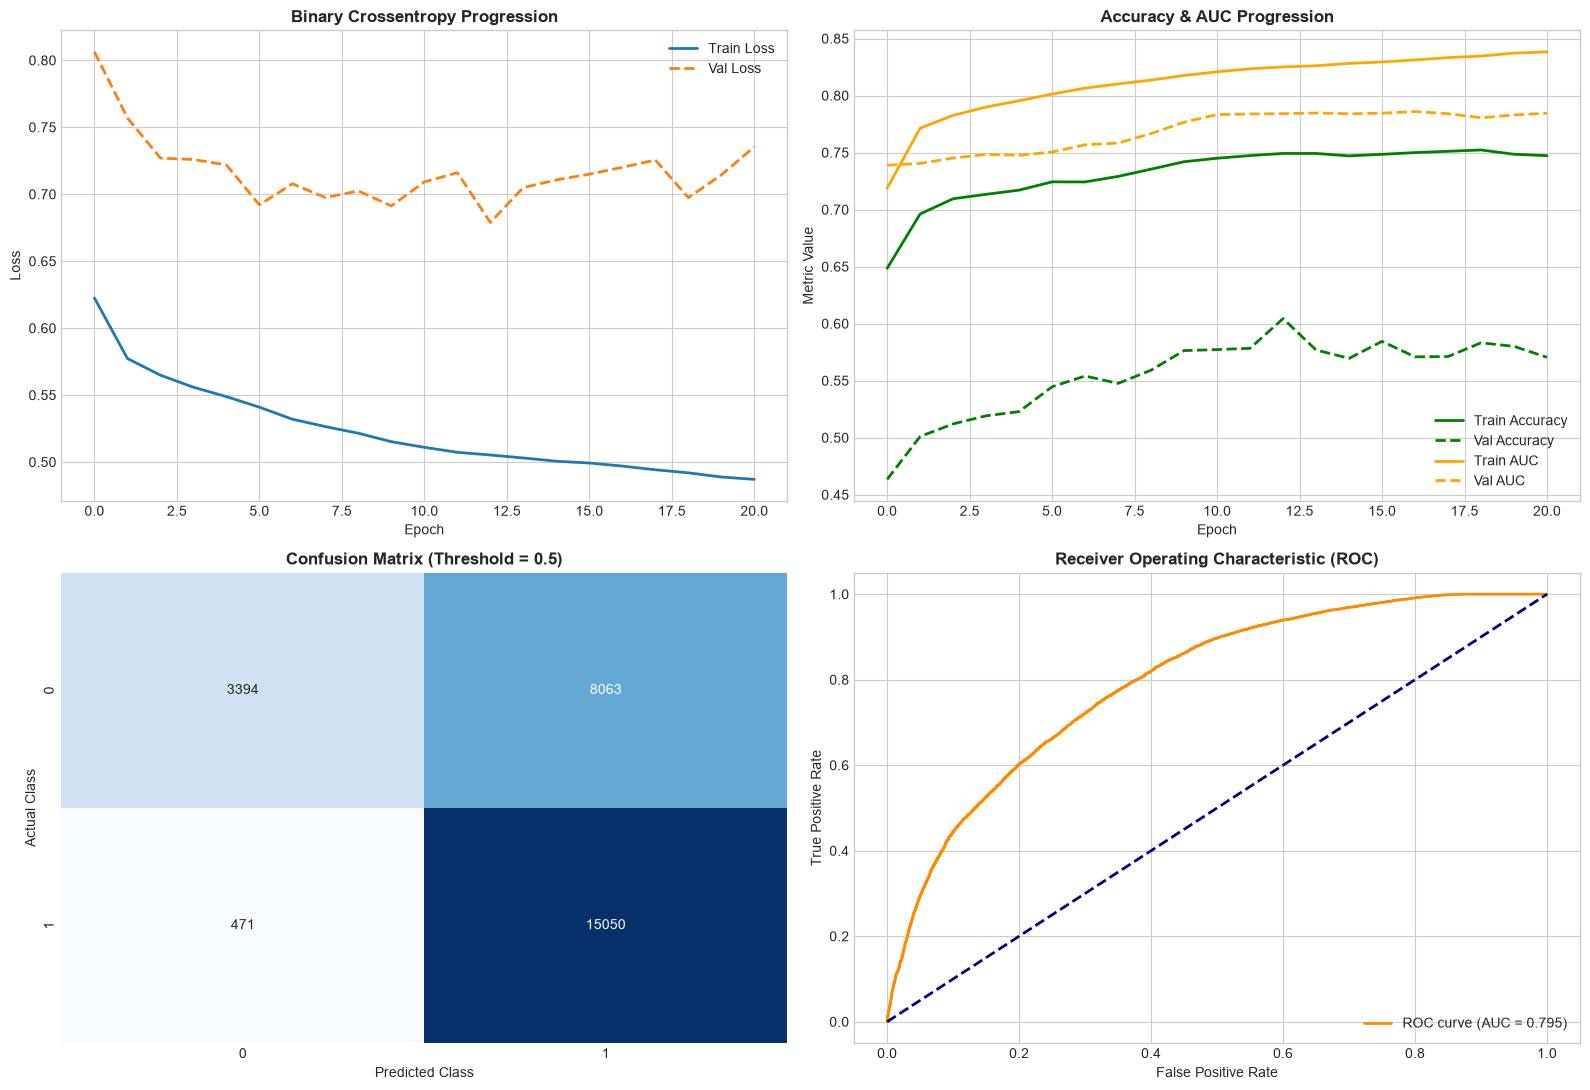

In [35]:
import matplotlib.pyplot as plt

# Evaluación sobre test: X_test ya viene con forma (muestras, WINDOW, features)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

df_preds, df_metrics = model_base.evaluate(
    model=history.model,
    history=history,
    X_test=X_test,
    y_test=y_test,
)

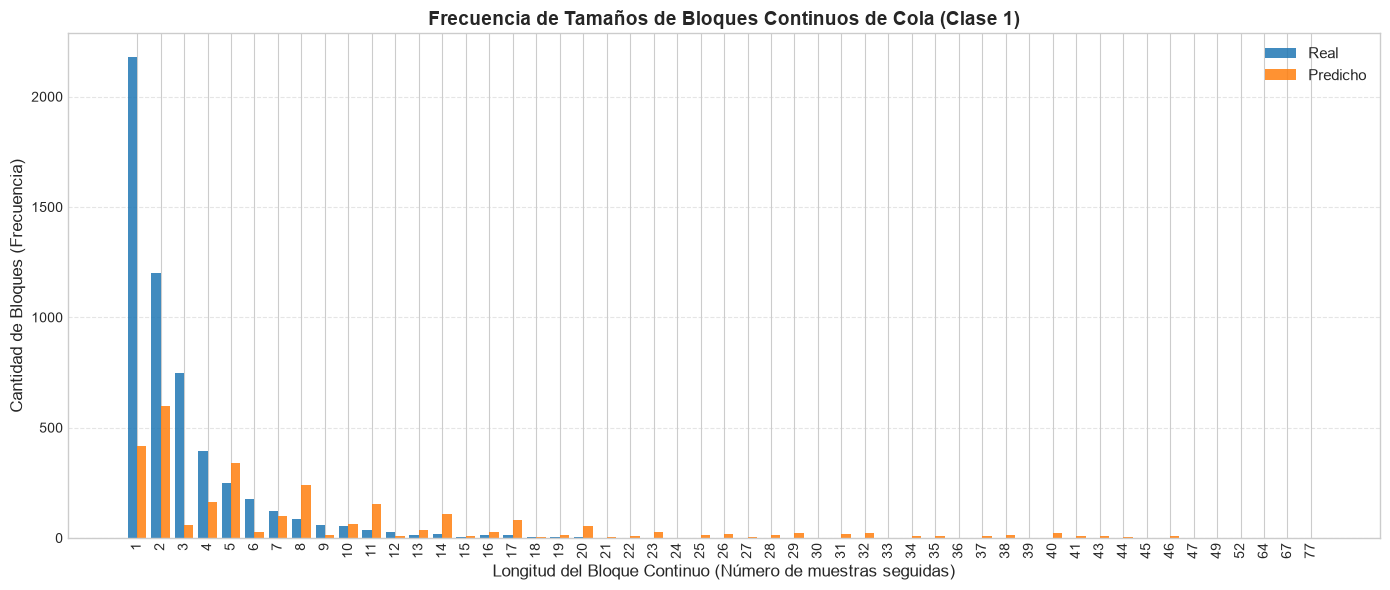

In [37]:
import matplotlib.pyplot as plt

def obtener_longitudes_bloques(series, clase=1):
    # Detecta cambios de estado para agrupar muestras consecutivas
    grupos = (series != series.shift()).cumsum()
    # Mide el tamaño de cada bloque si pertenece a la clase objetivo
    duraciones = series.groupby(grupos).apply(lambda g: len(g) if g.iloc[0] == clase else 0)
    return duraciones[duraciones > 0]

# 2. Obtener las duraciones para datos Reales y Predichos
bloques_reales = obtener_longitudes_bloques(df_preds['Actual'], clase=1)
bloques_predichos = obtener_longitudes_bloques(df_preds['Predicted Class'], clase=1)

# 3. Contar la frecuencia de cada tamaño de bloque (ej: cuántos bloques de 7, cuántos de 8, etc.)
freq_reales = bloques_reales.value_counts()
freq_predichos = bloques_predichos.value_counts()

# Combinar en un único DataFrame para graficar lado a lado
df_histograma = pd.DataFrame({
    'Real': freq_reales,
    'Predicho': freq_predichos
}).fillna(0).sort_index()

# 4. Mostrar resumen por consola (ej: "3 bloques de 8, 5 de 7")
# print("--- RESUMEN DE BLOQUES DE COLA (Real vs Predicho) ---")
# for longitud, row in df_histograma.iterrows():
#     if row['Real'] > 0 or row['Predicho'] > 0:
#         print(f"Longitud {int(longitud)} muestras: {int(row['Real'])} bloques Reales | {int(row['Predicho'])} bloques Predichos")

# 5. Graficar Histograma de Frecuencias
plt.figure(figsize=(14, 6))
ancho_barra = 0.4
x = np.arange(len(df_histograma))

plt.bar(x - ancho_barra/2, df_histograma['Real'], width=ancho_barra, label='Real', color='#1f77b4', alpha=0.85)
plt.bar(x + ancho_barra/2, df_histograma['Predicho'], width=ancho_barra, label='Predicho', color='#ff7f0e', alpha=0.85)

plt.title('Frecuencia de Tamaños de Bloques Continuos de Cola (Clase 1)', fontsize=14, fontweight='bold')
plt.xlabel('Longitud del Bloque Continuo (Número de muestras seguidas)', fontsize=12)
plt.ylabel('Cantidad de Bloques (Frecuencia)', fontsize=12)

# Ajustar etiquetas del eje X con las longitudes reales
plt.xticks(x, labels=[str(int(i)) for i in df_histograma.index], rotation=90 if len(df_histograma) > 20 else 0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()

plt.show()